In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# Regulation and productivity: Italy in the OECD product market and employment protection indices
Candidate institutional explanations of Italy's productivity gap (notebooks 08, 13, 23): rules that limit competition (product market regulation, PMR) and rules on dismissals (employment protection, EPL). Data: the OECD indices via the SDMX API (`sources/oecd_regulation.py`; scale 0-6, higher = more restrictive).
- **PMR** exists here in two waves, **2018 and 2023**, for 57 economies (all EU27), with sector indicators for professions, retail, energy, transport and e-communications. There is no earlier wave in this flow, so it is a cross-section.
- **EPL** is annual, **1985-2019** (VERSION1; later years repeat), 21-22 EU members from the 1990s.
- **CompNet** (firm-level productivity dispersion) is only available on request from IWH Halle (form), so it is not used.
**Test (sector level, so there are more than 30 observations):** is the productivity growth of a sector in a country (log growth per year of real value added per hour, 2005-07 to 2017-19, EU KLEMS-style `sectors64`) related to the regulation of *that* sector in 2018? Six sectors have a matching PMR indicator (retail, legal and accounting, architecture and engineering, land transport, telecommunications, electricity and gas), 17-26 countries each. Within each sector both variables are ranks (so sector levels drop out); pooled correlation; p-value from shuffling the regulation across the countries of each sector; Benjamini-Hochberg over the pooled test and the six sector tests; shuffled-regulation null; Italy by placebo ranking, not by a test. PMR is measured at the *end* of the growth window, so the association cannot tell which came first. **Associations only, never causal.** Code: `src/cifresignificative/analysis/regulation.py`, `experiments.run_regulation_all`.

PMR, Italy against the other EU27 members (rank 1 = most restrictive; waves 2018 and 2023):


italy       median_others        rank      
year                2018  2023          2018  2023  2018  2023
measure                                                       
PMR                 1.29  1.23          1.47  1.22  16.0  13.0
STATE_INVOL         1.25  1.22          1.52  1.31  19.0  17.0
INVOL_BUSINESS      1.29  1.18          1.23  1.07  12.0  13.0
BARRIER_ENTRY       1.32  1.24          1.40  1.19  18.0  12.0
NETWORK_SECTORS     0.90  0.70          1.27  1.09  25.0  25.0
SERVBARRIER         3.03  3.03          1.96  1.96   4.0   5.0
PUBLIC_PROCUREMENT  1.10  0.70          0.60  0.50   4.0   7.0
ADBURDEN            1.80  1.80          2.24  1.92  19.0  15.0
LAWYERS             2.84  2.84          3.61  3.43  23.0  22.0
ACCOUNTANTS         2.82  2.82          0.08  0.22   1.0   1.0
ARCHITECTS          3.21  3.21          1.98  1.98   2.0   1.0
ENGINEERS           1.82  1.82          1.56  1.56  11.0  11.0
NOTARIES            4.14  4.14          5.36  5.36  19.0  19.0
RETAIL_TRADE        1.93  1.93          1.05  1.07   6.0   6.0
ENERGY              0.85  0.72          1.35  1.06  22.0  22.0
TRANSPORT           0.81  0.64          1.13  0.99  23.0  26.0
ECOMM               1.03  0.74          1.34  1.21  22.0  21.0

EPL overall (VERSION1), Italy vs the median of the other EU members present, and Italy's rank (1 = strictest):


year,1985,1990,1995,2000,2005,2010,2015,2019
italy,3.02,3.02,3.02,3.02,3.02,3.02,2.93,2.56
median_others,2.68,2.62,2.60,2.54,2.40,2.36,2.31,2.29
n_others,12.00,14.00,16.00,16.00,16.00,19.00,22.00,21.00
rank,4.00,4.00,5.00,5.00,4.00,4.00,5.00,7.00


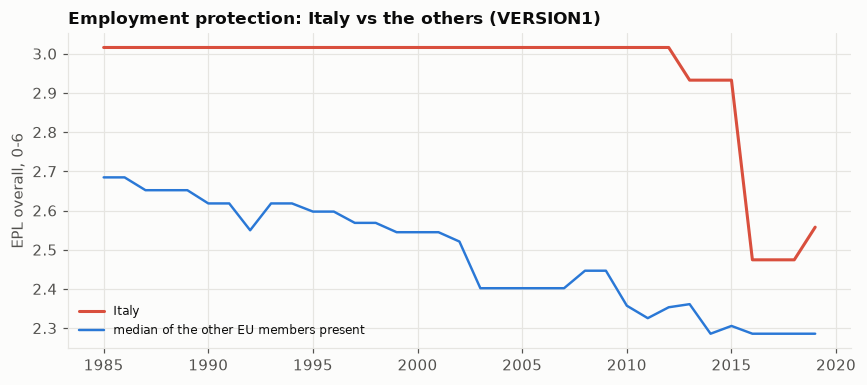

In [2]:
from cifresignificative.analysis import regulation as RGL, experiments as ex
res = ex.run_regulation_all()
pos = res["g1_pmr_position"]
print("PMR, Italy against the other EU27 members (rank 1 = most restrictive; waves 2018 and 2023):")
display(pos.pivot(index="measure", columns="year", values=["italy", "median_others", "rank"]).loc[RGL.POSITION].round(2))
e = res["g2_epl_gap"].set_index("year")
print("EPL overall (VERSION1), Italy vs the median of the other EU members present, and Italy's rank (1 = strictest):"); display(e.loc[[1985, 1990, 1995, 2000, 2005, 2010, 2015, 2019]].round(2).T)
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.plot(e.index, e.italy, color="#d94f3d", lw=2, label="Italy"); ax.plot(e.index, e.median_others, color="#2a78d6", lw=1.6, label="median of the other EU members present")
ax.set_ylabel("EPL overall, 0-6"); ax.set_title("Employment protection: Italy vs the others (VERSION1)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## G3 - does a sector's regulation go with its productivity growth?
Primary family: window 2005-07 to 2017-19 with PMR 2018 (pooled + six sectors, BH over these seven rows). The other rows are robustness (early and late halves of the growth window, PMR 2023) and are descriptive.

primary family (rho = Spearman of growth on regulation within sector; negative = more regulated sectors grow more slowly):


,sector,n,rho,p,q_value,significant
0,pooled,123,0.076,0.412,0.632,False
1,D,26,-0.013,0.953,0.967,False
2,G47,18,0.011,0.967,0.967,False
3,H49,17,0.203,0.434,0.632,False
4,J61,25,0.155,0.451,0.632,False
5,M69_M70,19,-0.246,0.306,0.632,False
6,M71,18,0.380,0.121,0.632,False


pooled test by window and PMR wave (descriptive):


,window,pmr_year,n,rho,p
0,full,2018,123,0.076,0.412
7,full,2023,123,0.102,0.271
14,early,2018,123,0.230,0.012
21,early,2023,123,0.233,0.011
28,late,2018,127,-0.141,0.119
35,late,2023,127,-0.072,0.429


sector tests with p < 0.05 in each specification: {('early', 2018): 2, ('early', 2023): 1, ('full', 2018): 0, ('full', 2023): 0, ('late', 2018): 0, ('late', 2023): 0}


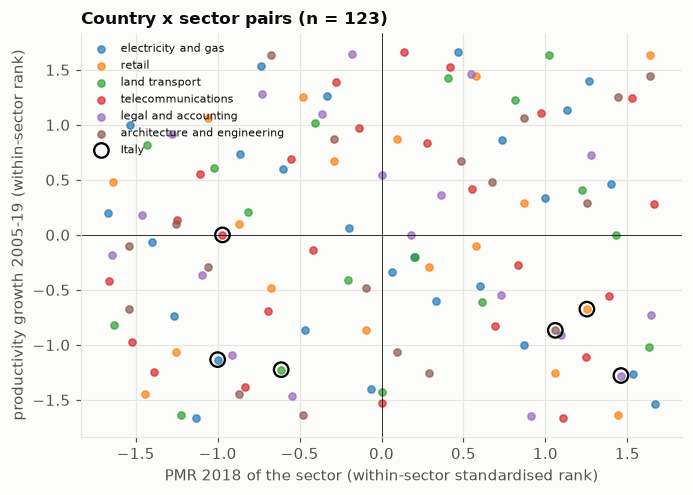

shuffled regulation within sectors, 200 repetitions: discoveries per repetition 0.07 | repetitions with a discovery 0.055 | share of tests with p < 0.05 0.056


In [3]:
g3 = res["g3_sector_test"]
print("primary family (rho = Spearman of growth on regulation within sector; negative = more regulated sectors grow more slowly):"); display(g3[g3.primary][["sector", "n", "rho", "p", "q_value", "significant"]].round(3))
print("pooled test by window and PMR wave (descriptive):"); display(g3[g3.sector == "pooled"][["window", "pmr_year", "n", "rho", "p"]].round(3))
print("sector tests with p < 0.05 in each specification:", g3[g3.sector != "pooled"].groupby(["window", "pmr_year"]).apply(lambda x: int((x.p < 0.05).sum())).to_dict())
from cifresignificative.sources import oecd_regulation as OR
d = RGL.sector_data(OR.load_pmr())
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for k, (code, grp) in enumerate(d.groupby("nace_r2")):
    ax.scatter(grp.rr, grp.rg, s=22, alpha=0.7, label=RGL.SECTORS[str(code)][0])
it = d[d.iso3 == "ITA"]; ax.scatter(it.rr, it.rg, s=90, facecolors="none", edgecolors="k", lw=1.5, label="Italy")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5); ax.set_xlabel("PMR 2018 of the sector (within-sector standardised rank)"); ax.set_ylabel("productivity growth 2005-19 (within-sector rank)"); ax.legend(fontsize=7)
ax.set_title("Country x sector pairs (n = %d)" % len(d)); plt.tight_layout(); plt.show()
n0 = res["g6_null"].iloc[0]; print("shuffled regulation within sectors,", int(n0.n_rep), "repetitions: discoveries per repetition", round(float(n0.mean_discoveries), 3), "| repetitions with a discovery", round(float(n0.share_reps_with_discovery), 3), "| share of tests with p < 0.05", round(float(n0.mean_share_p_below_005), 3))

## G4 - where is Italy?
Italy's regulation rank (1 = most restrictive) and productivity-growth rank (1 = fastest) in each sector, and a placebo ranking: for each country, the mean over its sectors of (growth rank minus the pooled slope times regulation rank); negative = slower growth than the pooled relation predicts.

In [4]:
display(res["g4_italy_sectors"].round(2))
pl = res["g5_italy_placebo"]
print("placebo ranking of the mean gap (1 = most negative), Italy:", pl[pl.iso3 == "ITA"][["gap", "rank", "n_countries", "pooled_slope"]].round(3).to_dict("records"))
print("the five most negative:"); display(pl.head(5).round(3))

,nace_r2,label,n,reg_italy,reg_median_others,reg_rank,growth_italy_pct,growth_median_others_pct,growth_rank
0,D,electricity and gas,26,0.85,1.34,21,-1.71,0.11,22
1,G47,retail,18,1.93,1.03,3,1.19,1.77,13
2,H49,land transport,17,1.19,1.38,12,-1.39,0.26,15
3,J61,telecommunications,25,1.03,1.30,20,3.74,3.72,13
4,M69_M70,legal and accounting,19,2.83,1.98,2,-0.77,0.18,17
5,M71,architecture and engineering,18,2.52,1.95,4,-1.91,-0.31,14


placebo ranking of the mean gap (1 = most negative), Italy: [{'gap': -0.878, 'rank': 3, 'n_countries': 18, 'pooled_slope': 0.076}]
the five most negative:


,iso3,gap,rank,n_countries,pooled_slope
0,GRC,-1.313,1,18,0.076
1,CYP,-1.140,2,18,0.076
2,ITA,-0.878,3,18,0.076
3,HRV,-0.605,4,18,0.076
4,AUT,-0.225,5,18,0.076


## Takeaways (OECD PMR 2018 and 2023, EPL 1985-2019; sector productivity growth 2005-07 to 2017-19; descriptive associations)
- **Product market regulation: mid-table overall, restrictive in professions and retail, light in network industries.** Italy's overall PMR is 1.29 in 2018 (median of the other EU27 1.47, rank 16 of 27, 1 = most restrictive) and 1.23 in 2023 (median 1.22, rank 13). It is among the most restrictive in accountants (2.82 against a median of 0.08 to 0.22, rank 1 in both waves), architects (3.21, rank 2 then 1), services barriers (3.03 against 1.96, rank 4-5), retail trade (1.93 against 1.05, rank 6) and public procurement (rank 4, then 7 after a fall from 1.10 to 0.70), and among the least restrictive in network sectors (rank 25 of 27), energy (22), transport (23 to 26) and e-communications (21-22). Lawyers (rank 22-23) and notaries (19) are below the median. The professions' indicators are identical in the two waves (the rules did not change); the changes between waves are in network sectors, procurement and entry barriers.
- **Employment protection: high and constant until 2010, then lower.** The overall EPL index (VERSION1) is 3.02 from 1985 to 2010 (median of the other EU members present 2.68 falling to 2.36; rank 4-5), 2.93 in 2015 and 2.56 in 2019 (median 2.29, rank 7 of 22). The OECD's newer version (VERSION4, from 2013) has a one-year spike in 2021 for Italy (3.82 against 2.86 either side), driven by collective dismissals (6.00, the scale's maximum, against 3.19) and, less, regular contracts (2.94 against 2.72); temporary contracts do not move, no EU member shows it (the only other economy is Turkey, +3.05), and the 2020 and 2022 values are unchanged. That pattern fits the Covid-period ban on dismissals (2020-21; dates from memory) read at 1 January 2021, but the OECD's note was not checked and the series are not spliced.
- **No relation between a sector's regulation and its productivity growth.** Across 123 country x sector pairs (six sectors, 17-26 countries each) the pooled within-sector rank correlation between the 2018 PMR indicator and productivity growth is +0.08 (permutation p 0.41, q 0.63), and none of the six sectors is significant (smallest q 0.63; rho from -0.25 for legal and accounting to +0.38 for architecture and engineering, both n = 18-19). The sign is not stable: +0.23 in the early half of the window (p 0.012, q 0.07, in the wrong direction for a drag from regulation), -0.14 in the late half (p 0.12). Shuffling the regulation within sectors gives 0.07 discoveries per repetition (200 repetitions), so the procedure does not manufacture them. With about 123 pairs a correlation below roughly 0.18 in absolute value (1.96 / sqrt(122), an approximation) cannot be told from zero: the test rules out a strong sector-level link, not a weak one. PMR is measured at the end of the window, and the matched indicators are coarse (one rule set per profession, one retail index).
- **Italy's sectors grow slowly whatever their regulation.** Italy's productivity growth is 22nd of 26 in electricity and gas (-1.7% a year against a median of +0.1%), 17th of 19 in legal and accounting (-0.8% against +0.2%), 15th of 17 in land transport and 14th of 18 in architecture and engineering; it is mid-table in retail (13th of 18) and telecommunications (13th of 25). Its regulation rank in those sectors differs widely (2nd of 19 in legal and accounting, 4th in architecture and engineering, 3rd in retail, but 21st in electricity and gas), and the pooled slope is near zero. In the placebo ranking of the mean gap between growth rank and the pooled relation, Italy has the 3rd most negative gap of 18 countries (after Greece and Cyprus), which here only says that its sector productivity growth is low across these sectors.
- **Limits.** Two PMR waves only (no earlier vintage in this flow), measured at the end of the growth window; six sectors with matched indicators (marketed services and utilities, not manufacturing); within-sector sample sizes of 17-26; sector growth is computed from 2-digit value added per hour with missing hours for several countries; regulation and productivity can move together for other reasons (country size, development, measurement). CompNet (firm-level dispersion) is available only on request from IWH Halle. Nothing here is causal.
